## Importing libraries and data

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import shap
from sklearn.inspection import permutation_importance

In [ ]:
train_data = pd.read_csv("/content/drive/MyDrive/Applied Machine Learning/AppML_InitialProject_train.csv")

In [ ]:
train_data.head()

,averageInteractionsPerCrossing,p_Rhad1,p_Rhad,p_f3,p_weta2,p_Rphi,p_Reta,p_Eratio,p_f1,p_TRTPID,...,pX_E7x11_Lr2,pX_E7x11_Lr3,pX_E7x7_Lr0,pX_E7x7_Lr1,p_pt_track,p_eta,p_phi,p_charge,p_Truth_isElectron,p_Truth_Energy
0,55.50,-0.002390,-0.003614,0.000744,0.010088,0.947685,0.983722,0.969448,0.355275,-0.030026,...,27951.328,473.046360,1415.2955,16208.0300,38339.875,0.725108,2.511338,-1.0,1,46673.574
1,33.50,-0.009279,-0.010666,0.003784,0.011625,0.922366,0.955934,0.918366,0.397633,0.335419,...,34642.820,86.462740,11456.5240,28639.7420,26470.890,1.566765,-0.593568,-1.0,1,85356.500
2,35.50,0.002806,0.013643,0.025505,0.010330,0.969845,0.945576,0.921568,0.077971,0.517517,...,88892.890,2173.160200,0.0000,8061.6840,32989.957,1.926261,2.497809,-1.0,1,103427.160
3,40.49,-0.001910,0.000044,0.000176,0.010323,0.923816,0.888029,0.000000,0.000000,0.133801,...,39768.450,102.033676,35418.3050,27154.4340,86615.234,1.510641,2.441266,-1.0,1,163799.640
4,52.50,0.013779,-0.002106,0.010156,0.010096,0.899883,0.717177,0.782584,0.253658,-0.044038,...,15531.818,277.199130,1242.5723,6206.0938,17362.506,-0.113342,3.003595,-1.0,1,16997.960


In [ ]:
train_data.describe()

,averageInteractionsPerCrossing,p_Rhad1,p_Rhad,p_f3,p_weta2,p_Rphi,p_Reta,p_Eratio,p_f1,p_TRTPID,...,pX_E7x11_Lr2,pX_E7x11_Lr3,pX_E7x7_Lr0,pX_E7x7_Lr1,p_pt_track,p_eta,p_phi,p_charge,p_Truth_isElectron,p_Truth_Energy
count,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,...,180000.000000,180000.000000,180000.000000,180000.000000,1.800000e+05,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000
mean,36.159946,0.220708,0.381036,0.039468,0.012939,0.799293,0.919739,0.494159,0.241862,0.010309,...,45500.480319,3905.137032,4531.675282,17153.894820,2.184704e+04,0.005892,-0.015323,0.008133,0.210000,38871.649839
std,10.954592,0.310926,0.518678,0.078373,0.004539,1.133489,57.077856,0.349076,0.126738,0.199531,...,39290.076155,7446.819363,5845.719673,14785.697261,3.196349e+05,1.315961,1.808330,0.999970,0.407309,43924.098296
min,0.500000,-0.326666,-0.372617,-0.026269,-0.071970,-179.215070,-733.199400,0.000000,-1.209092,-0.802563,...,-1263.775400,-2622.452100,-5675.989300,-14909.946000,4.859259e+02,-2.523115,-3.141566,-1.000000,0.000000,-999.000000
25%,28.500000,0.015493,0.029692,0.005844,0.010666,0.716915,0.701692,0.162990,0.162924,-0.102265,...,21795.727500,414.223403,628.415152,7922.023875,7.029497e+03,-1.100936,-1.579656,-1.000000,0.000000,11397.750250
50%,36.500000,0.111860,0.203688,0.013380,0.012484,0.824988,0.813324,0.473347,0.252859,-0.000000,...,32663.150500,1305.569500,2443.186400,12615.856500,1.448449e+04,0.009985,-0.031125,1.000000,0.000000,25552.606500
75%,44.490000,0.306133,0.537789,0.038510,0.014658,0.908142,0.907448,0.857762,0.332105,0.082940,...,54076.836500,4081.974500,6320.987525,20962.022000,2.617526e+04,1.108476,1.544746,1.000000,0.000000,49998.562250
max,59.500000,10.187515,17.054897,1.474104,0.093692,378.033800,24198.590000,1.000000,0.809841,2.295615,...,889313.060000,234937.300000,159025.270000,284725.250000,1.188614e+08,2.521093,3.141570,1.000000,1.000000,871351.500000


In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Columns: 142 entries, averageInteractionsPerCrossing to p_Truth_Energy
dtypes: float64(121), int64(21)
memory usage: 195.0 MB


In [ ]:
train_data.isnull().sum()

,0
averageInteractionsPerCrossing,0
p_Rhad1,0
p_Rhad,0
p_f3,0
p_weta2,0
...,...
p_eta,0
p_phi,0
p_charge,0
p_Truth_isElectron,0


In [ ]:
train_data.isna().sum().sum()

np.int64(0)

The possibility of any inconsistency checked and there is no null values in our data and all value-types are int and/or float. Therefore, we can skip the basic preprocessing of the data.

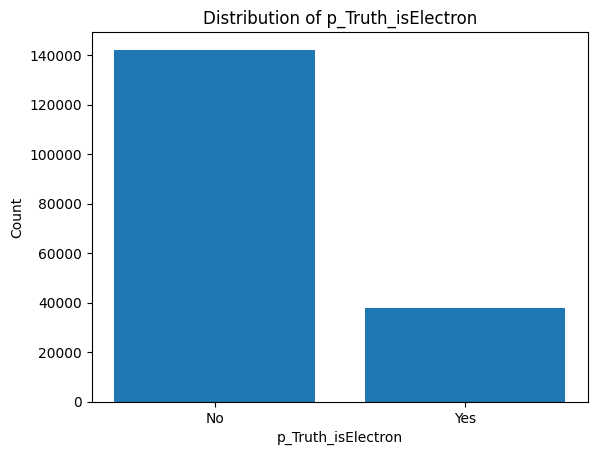

In [ ]:
# Calculate the value counts for 'p_Truth_isElectron'
value_counts = train_data['p_Truth_isElectron'].value_counts()

# Create the bar plot
plt.bar(value_counts.index, value_counts.values)
plt.xlabel('p_Truth_isElectron')
plt.ylabel('Count')
plt.title('Distribution of p_Truth_isElectron')
plt.xticks(value_counts.index, ['No', 'Yes'])
plt.show()

In [ ]:
value_counts

,count
p_Truth_isElectron,
0,142200
1,37800


In [ ]:
features = train_data.drop(columns=['p_Truth_isElectron','p_Truth_Energy'])
target = train_data['p_Truth_isElectron']

features_labels = features.columns
target_labels = target.name

In [ ]:
features_labels

Index(['averageInteractionsPerCrossing', 'p_Rhad1', 'p_Rhad', 'p_f3',
       'p_weta2', 'p_Rphi', 'p_Reta', 'p_Eratio', 'p_f1', 'p_TRTPID',
       ...
       'pX_E7x11_Lr0', 'pX_E7x11_Lr1', 'pX_E7x11_Lr2', 'pX_E7x11_Lr3',
       'pX_E7x7_Lr0', 'pX_E7x7_Lr1', 'p_pt_track', 'p_eta', 'p_phi',
       'p_charge'],
      dtype='object', length=140)

## LGBM Model

In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.metrics import confusion_matrix
import lightgbm as lgb
from lightgbm import early_stopping
import time
from lightgbm import LGBMClassifier

In [ ]:
start = time.time()

X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

model = LGBMClassifier()

In [ ]:
model.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 30326, number of negative: 113674
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.481124 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 29754
[LightGBM] [Info] Number of data points in the train set: 144000, number of used features: 138
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.210597 -> initscore=-1.321329
[LightGBM] [Info] Start training from score -1.321329


LGBMClassifier()

## Feature Importance


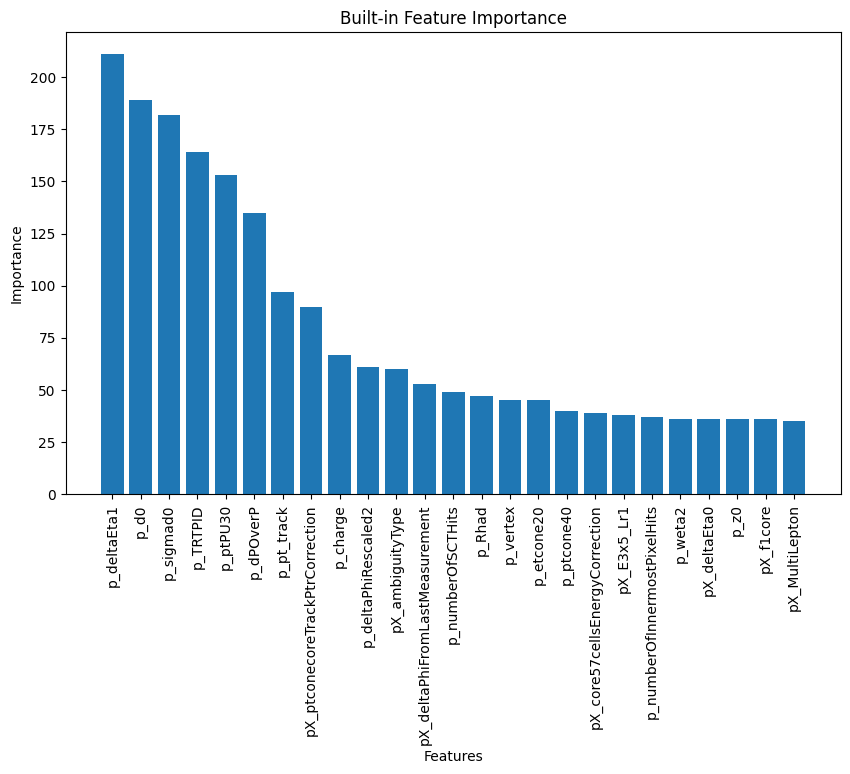

In [ ]:
built_in_importance = model.feature_importances_
built_in_importance = pd.DataFrame(built_in_importance, index=features_labels, columns=['Importance'])
built_in_importance = built_in_importance.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(built_in_importance.index[:25], built_in_importance['Importance'][:25])
plt.xlabel('Features')
plt.ylabel('Importance')
plt.title('Built-in Feature Importance')
plt.xticks(rotation=90)
plt.show()

In [ ]:
p_importance = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)

p_importance = pd.DataFrame(p_importance.importances_mean, index=features_labels, columns=['Importance'])
p_importance = p_importance.sort_values(by='Importance', ascending=False)

p_importance

,Importance
p_sigmad0,0.015408
p_TRTPID,0.009939
p_ptPU30,0.006936
p_numberOfInnermostPixelHits,0.006719
p_deltaEta1,0.004678
...,...
pX_E5x7_Lr2,-0.000089
pX_E_Lr3_HiG,-0.000103
pX_etcone20,-0.000111
pX_ptvarcone40,-0.000119


([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24],
 [Text(0, 0, 'p_sigmad0'),
  Text(1, 0, 'p_TRTPID'),
  Text(2, 0, 'p_ptPU30'),
  Text(3, 0, 'p_numberOfInnermostPixelHits'),
  Text(4, 0, 'p_deltaEta1'),
  Text(5, 0, 'p_d0'),
  Text(6, 0, 'pX_MultiLepton'),
  Text(7, 0, 'pX_ptconecoreTrackPtrCorrection'),
  Text(8, 0, 'p_dPOverP'),
  Text(9, 0, 'p_charge'),
  Text(10, 0, 'p_etcone20'),
  Text(11, 0, 'p_pt_track'),
  Text(12, 0, 'p_numberOfSCTHits'),
  Text(13, 0, 'p_deltaPhiRescaled2'),
  Text(14, 0, 'p_Rhad'),
  Text(15, 0, 'pX_deltaPhiFromLastMeasurement'),
  Text(16, 0, 'pX_ambiguityType'),
  Text(17, 0, 'p_ptcone40'),
  Text(18, 0, 'p_f3'),
  Text(19, 0, 'pX_core57cellsEnergyCorrection'),
  Text(20, 0, 'p_f1'),
  Text(21, 0, 'pX_E_Lr0_HiG'),
  Text(22, 0, 'p_vertex'),
  Text(23, 0, 'pX_f1core'),
  Text(24, 0, 'pX_E5x7_Lr1')])

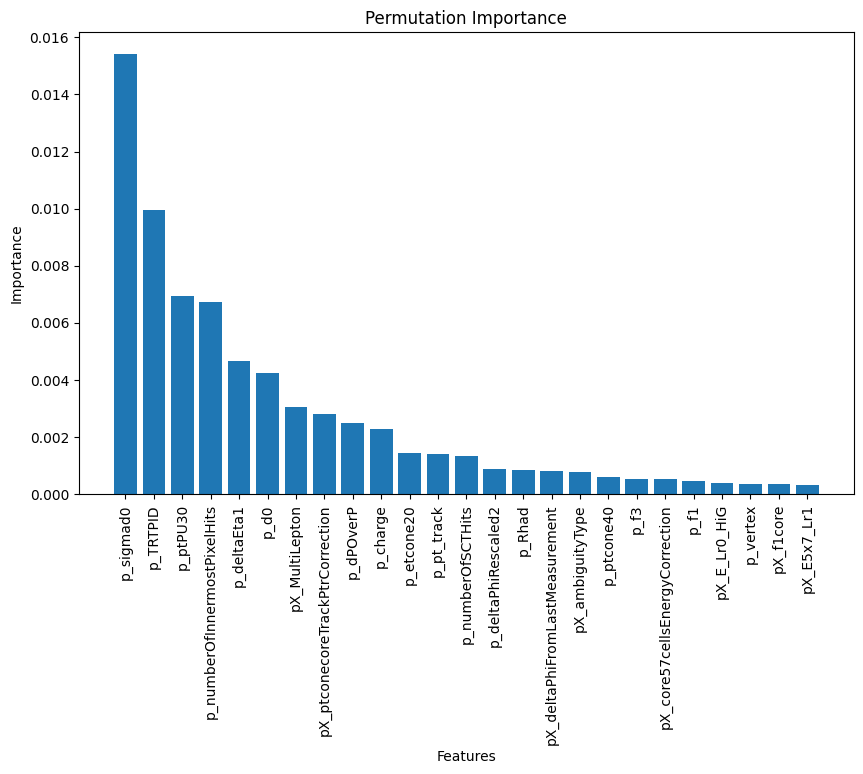

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(p_importance.index[:25], p_importance['Importance'][:25])
plt.xlabel('Features')
plt.ylabel('Importance')
plt.title('Permutation Importance')
plt.xticks(rotation=90)

In [ ]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

/usr/local/lib/python3.11/dist-packages/shap/explainers/_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


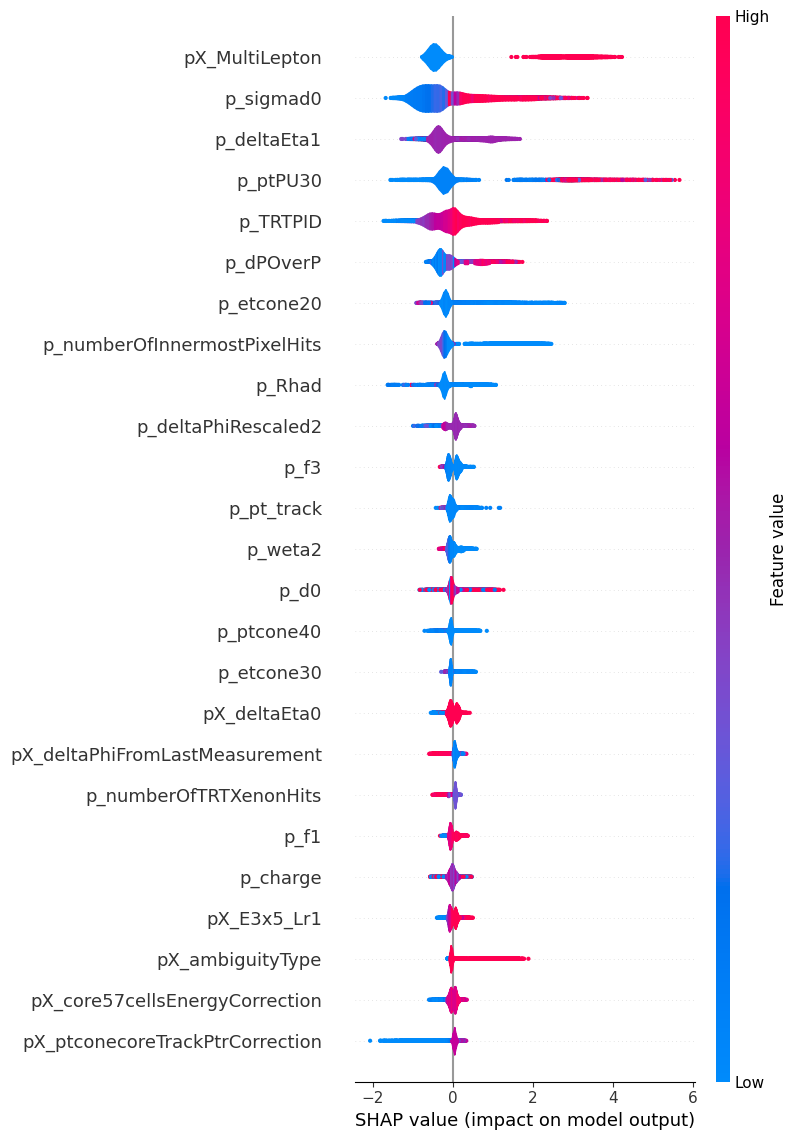

In [ ]:
shap.summary_plot(shap_values, X_test, feature_names=features_labels, plot_type='violin', max_display=25)
plt.show()

Ranking features

In [ ]:
shap_importance = pd.DataFrame(np.abs(shap_values).mean(axis=0), index=features_labels, columns=['SHAP']).sort_values(by='SHAP', ascending=False)
shap_importance

,SHAP
pX_MultiLepton,0.790737
p_sigmad0,0.727893
p_deltaEta1,0.476521
p_ptPU30,0.466210
p_TRTPID,0.455555
...,...
pX_nCells_Lr1_LowG,0.000000
pX_nCells_Lr3_MedG,0.000000
pX_nCells_Lr2_LowG,0.000000
pX_nCells_Lr2_MedG,0.000000


In [ ]:
type(p_importance)

pandas.core.frame.DataFrame

In [ ]:
ranks_df = pd.DataFrame({
    'built_in': built_in_importance['Importance'].rank(ascending=False),
    'permutation': p_importance['Importance'].rank(ascending=False),
    'shap': shap_importance['SHAP'].rank(ascending=False)
}, index=built_in_importance.index)

# Average ranks
ranks_df['mean_rank'] = ranks_df.mean(axis=1)

# Select top 25 features
top_25_features = ranks_df.sort_values(by='mean_rank').head(25).index.tolist()
variables_list = ranks_df.sort_values(by='mean_rank').head(25)
print(top_25_features)


['p_sigmad0', 'p_deltaEta1', 'p_TRTPID', 'p_ptPU30', 'p_dPOverP', 'p_d0', 'p_pt_track', 'p_numberOfInnermostPixelHits', 'pX_MultiLepton', 'p_etcone20', 'p_deltaPhiRescaled2', 'p_Rhad', 'p_charge', 'pX_ptconecoreTrackPtrCorrection', 'pX_deltaPhiFromLastMeasurement', 'p_ptcone40', 'pX_ambiguityType', 'p_f3', 'pX_core57cellsEnergyCorrection', 'p_weta2', 'pX_E3x5_Lr1', 'p_f1', 'p_numberOfSCTHits', 'pX_f1core', 'p_vertex']


In [ ]:
variables_list.index
variables_list = pd.DataFrame(variables_list.index, columns=['Variable'])
variables_list

,Variable
0,p_sigmad0
1,p_deltaEta1
2,p_TRTPID
3,p_ptPU30
4,p_dPOverP
5,p_d0
6,p_pt_track
7,p_numberOfInnermostPixelHits
8,pX_MultiLepton
9,p_etcone20


In [ ]:
variables_list.to_csv('/content/drive/MyDrive/Applied Machine Learning/solutions/Classification_MohammadhadiShahhosseini_VariableList.csv', index=False, header = False)

In [ ]:
X_train_new = X_train[top_25_features]
X_test_new = X_test[top_25_features]

## Hyperparameters Optimization

In [ ]:
!pip install bayesian-optimization

In [ ]:
from bayes_opt import BayesianOptimization
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [ ]:
def LGBM_CrossValidation(num_leaves, max_depth, learning_rate, min_child_samples,
                         subsample, colsample_bytree, reg_alpha, reg_lambda,
                         data, targets, cv_folds=5):
    """Cross-validated accuracy for LGBMClassifier with given hyperparameters."""

    model = LGBMClassifier(
        num_leaves=int(round(num_leaves)),
        max_depth=int(round(max_depth)),
        learning_rate=learning_rate,
        min_child_samples=int(round(min_child_samples)),
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        reg_alpha=reg_alpha,
        reg_lambda=reg_lambda,
        objective='binary',
        random_state=42,
        n_estimators=1000,  # large number with early stopping if added later
        n_jobs=-1
    )

    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    scores = cross_val_score(model, data, targets, cv=cv, scoring='accuracy', n_jobs=-1)

    return scores.mean()

In [ ]:
def optimize_LGBM(data, targets, n_iter=25):
    """Bayesian Optimization of LGBMClassifier hyperparameters."""

    def crossval_wrapper(num_leaves, max_depth, learning_rate,
                         min_child_samples, subsample, colsample_bytree,
                         reg_alpha, reg_lambda):
        try:
            return LGBM_CrossValidation(
                num_leaves=num_leaves,
                max_depth=max_depth,
                learning_rate=learning_rate,
                min_child_samples=min_child_samples,
                subsample=subsample,
                colsample_bytree=colsample_bytree,
                reg_alpha=reg_alpha,
                reg_lambda=reg_lambda,
                data=data,
                targets=targets
            )
        except Exception as e:
            print("Error:", e)
            return 0

    param_bounds = {
        'num_leaves': (20, 150),
        'max_depth': (3, 15),
        'learning_rate': (0.01, 0.3),
        'min_child_samples': (5, 50),
        'subsample': (0.5, 1.0),
        'colsample_bytree': (0.5, 1.0),
        'reg_alpha': (1e-8, 10.0),
        'reg_lambda': (1e-8, 10.0)
    }

    optimizer = BayesianOptimization(
        f=crossval_wrapper,
        pbounds=param_bounds,
        random_state=42,
        verbose=2
    )

    optimizer.maximize(init_points=5, n_iter=n_iter)

    return optimizer

In [ ]:
BayesOpt_LGBM = optimize_LGBM(X_train_new, y_train, n_iter=25)
print("Best Score and Parameters:")
print(BayesOpt_LGBM.max)

|   iter    |  target   | colsam... | learni... | max_depth | min_ch... | num_le... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------
| 1         | 0.974     | 0.6873    | 0.2857    | 11.78     | 31.94     | 40.28     | 1.56      | 0.5808    | 0.9331    |
| 2         | 0.9743    | 0.8006    | 0.2153    | 3.247     | 48.65     | 128.2     | 2.123     | 1.818     | 0.5917    |
| 3         | 0.974     | 0.6521    | 0.1622    | 8.183     | 18.11     | 99.54     | 1.395     | 2.921     | 0.6832    |
| 4         | 0.9743    | 0.728     | 0.2377    | 5.396     | 28.14     | 97.01     | 0.4645    | 6.075     | 0.5853    |
| 5         | 0.9735    | 0.5325    | 0.2852    | 14.59     | 41.38     | 59.6      | 0.9767    | 6.842     | 0.7201    |
| 6         | 0.9727    | 0.6903    | 0.2589    | 12.05     | 5.826     | 41.64     | 4.74      | 6.587     | 0.8576    |
| 7         | 0.9743    

## Final Model

In [ ]:
best_params = {
    'colsample_bytree': 0.8838,
    'learning_rate': 0.2175,
    'max_depth': int(round(13.366)),
    'min_child_samples': int(round(36.588)),
    'num_leaves': int(round(20.247)),
    'reg_alpha': 0.6986,
    'reg_lambda': 1.6147,
    'subsample': 0.8558
}

In [ ]:
final_model = LGBMClassifier(
    objective='binary',
    random_state=42,
    n_estimators=1000,
    n_jobs=-1,
    **best_params)

In [ ]:
final_model.fit(
    X_train_new,
    y_train,
    eval_set=[(X_test_new, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=100)]
)

[LightGBM] [Info] Number of positive: 30326, number of negative: 113674
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.075283 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4879
[LightGBM] [Info] Number of data points in the train set: 144000, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.210597 -> initscore=-1.321329
[LightGBM] [Info] Start training from score -1.321329
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[332]	valid_0's binary_logloss: 0.0674505


LGBMClassifier(colsample_bytree=0.8838, learning_rate=0.2175, max_depth=13,
               min_child_samples=37, n_estimators=1000, n_jobs=-1,
               num_leaves=20, objective='binary', random_state=42,
               reg_alpha=0.6986, reg_lambda=1.6147, subsample=0.8558)

In [ ]:
y_pred_prob = final_model.predict_proba(X_test_new)[:, 1]

y_pred_class = final_model.predict(X_test_new)

In [ ]:
from sklearn.metrics import log_loss, accuracy_score

print("Log Loss:", log_loss(y_test, y_pred_prob))
print("Accuracy:", accuracy_score(y_test, y_pred_class))

Log Loss: 0.06745054864212786
Accuracy: 0.9740555555555556


In [ ]:
y_pred_prob

array([5.09301505e-01, 5.35133225e-05, 9.98575600e-01, ...,
       7.27982183e-02, 7.83738602e-04, 2.11826895e-05])

## Prediction on Test Data

In [ ]:
test_data = pd.read_csv("/content/drive/MyDrive/Applied Machine Learning/AppML_InitialProject_test_classification.csv")

In [ ]:
test_data = test_data[top_25_features]

In [ ]:
test_data.head()

,p_sigmad0,p_deltaEta1,p_TRTPID,p_ptPU30,p_dPOverP,p_d0,p_pt_track,p_numberOfInnermostPixelHits,pX_MultiLepton,p_etcone20,...,p_ptcone40,pX_ambiguityType,p_f3,pX_core57cellsEnergyCorrection,p_weta2,pX_E3x5_Lr1,p_f1,p_numberOfSCTHits,pX_f1core,p_vertex
0,0.012406,-0.001190,0.118954,0.000000e+00,0.092284,-0.005397,36647.3500,1,1,0.062348,...,0.000000,0,0.005667,35792.023,0.011082,10320.3120,0.207761,8,0.124669,1
1,0.057154,-0.006406,0.334848,1.427523e-04,-0.060352,0.183885,2801.5720,0,0,0.714565,...,10.350828,0,0.019870,14687.061,0.012287,5829.3105,0.397367,7,0.136852,1
2,0.062318,0.063462,0.168309,0.000000e+00,0.204363,-0.051800,2049.2185,1,0,0.469450,...,3.283630,3,0.010028,30152.870,0.011124,12907.2250,0.288416,7,0.075312,1
3,0.015904,0.001025,0.276550,3.468879e-01,0.237477,0.015828,21780.4320,1,1,0.157164,...,0.000000,0,0.004713,36273.710,0.009167,12502.5490,0.301254,8,0.178223,1
4,2.668945,0.004196,0.400937,6.129685e-07,0.585771,-9.577252,3178.6943,0,0,-0.015953,...,0.700289,4,0.009684,23752.630,0.010108,22350.7830,0.309093,9,0.147188,0


In [ ]:
test_pred_prob = final_model.predict_proba(test_data)[:, 1]

In [ ]:
test_pred_prob

array([9.99757241e-01, 8.68668691e-01, 3.30826403e-01, ...,
       5.70243722e-03, 3.65346335e-05, 9.60107814e-04])

In [ ]:
submission = pd.DataFrame({'p_Truth_isElectron': test_pred_prob})
submission.reset_index()

,index,p_Truth_isElectron
0,0,0.999757
1,1,0.868669
2,2,0.330826
3,3,0.999969
4,4,0.965287
...,...,...
59995,59995,0.001127
59996,59996,0.000218
59997,59997,0.005702
59998,59998,0.000037


In [ ]:
submission.to_csv('/content/drive/MyDrive/Applied Machine Learning/solutions/Classification_MohammadhadiShahhosseini_lgbm.csv', index=True)

## TabNet

In [ ]:
!pip install pytorch-tabnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 61.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [ ]:
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
import torch


In [ ]:
# Encode target
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_new)
X_test_scaled = scaler.transform(X_test_new)


In [ ]:
clf_tabnet = TabNetClassifier(
    device_name='cuda' if torch.cuda.is_available() else 'cpu',
    seed=42,
    verbose=1
)

clf_tabnet.fit(
    X_train=X_train_scaled, y_train=y_train_enc,
    eval_set=[(X_test_scaled, y_test_enc)],
    eval_metric=['logloss'],
    max_epochs=100,
    patience=10,
    batch_size=1024,
    virtual_batch_size=128
)


/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.21828 | val_0_logloss: 0.15378 |  0:00:24s
epoch 1  | loss: 0.14437 | val_0_logloss: 0.14102 |  0:00:34s
epoch 2  | loss: 0.13339 | val_0_logloss: 0.12619 |  0:00:44s
epoch 3  | loss: 0.1243  | val_0_logloss: 0.12283 |  0:00:55s
epoch 4  | loss: 0.11978 | val_0_logloss: 0.12732 |  0:01:06s
epoch 5  | loss: 0.11617 | val_0_logloss: 0.1142  |  0:01:17s
epoch 6  | loss: 0.1143  | val_0_logloss: 0.11584 |  0:01:28s
epoch 7  | loss: 0.1107  | val_0_logloss: 0.11225 |  0:01:39s
epoch 8  | loss: 0.10905 | val_0_logloss: 0.11083 |  0:01:51s
epoch 9  | loss: 0.10536 | val_0_logloss: 0.1083  |  0:02:05s
epoch 10 | loss: 0.10291 | val_0_logloss: 0.10853 |  0:02:16s
epoch 11 | loss: 0.10285 | val_0_logloss: 0.1176  |  0:02:26s
epoch 12 | loss: 0.10505 | val_0_logloss: 0.11298 |  0:02:37s
epoch 13 | loss: 0.10492 | val_0_logloss: 0.10864 |  0:02:48s
epoch 14 | loss: 0.10211 | val_0_logloss: 0.10371 |  0:02:59s
epoch 15 | loss: 0.09961 | val_0_logloss: 0.09956 |  0:03:11s
epoch 16

/usr/local/lib/python3.11/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [ ]:
y_tabnet_pred = clf_tabnet.predict(X_test_scaled)
y_tabnet_prob = clf_tabnet.predict_proba(X_test_scaled)[:, 1]

from sklearn.metrics import accuracy_score, log_loss
print("TabNet Accuracy:", accuracy_score(y_test_enc, y_tabnet_pred))
print("TabNet Log Loss:", log_loss(y_test_enc, y_tabnet_prob))


TabNet Accuracy: 0.9662222222222222
TabNet Log Loss: 0.09102983864327176


In [ ]:
# Scale final test data
test_data_scaled = scaler.transform(test_data)

# Predict
final_tabnet_pred = clf_tabnet.predict(test_data_scaled)
final_tabnet_prob = clf_tabnet.predict_proba(test_data_scaled)[:, 1]

In [ ]:
final_tabnet_prob

array([9.9603552e-01, 8.8745451e-01, 2.1278854e-01, ..., 1.8030066e-02,
       3.2288625e-04, 8.3075436e-03], dtype=float32)

In [ ]:
y_train_pred = clf_tabnet.predict(X_train_scaled)
train_acc = accuracy_score(y_train_enc, y_train_pred)
print("Train Accuracy:", train_acc)

print("Test Accuracy:", accuracy_score(y_test_enc, y_tabnet_pred))


Train Accuracy: 0.9664861111111112
Test Accuracy: 0.9662222222222222


In [ ]:
submission_tabnet = pd.DataFrame({
    'vars': test_data.index,
    'pred': final_tabnet_prob
})
submission_tabnet

,vars,pred
0,0,0.996036
1,1,0.887455
2,2,0.212789
3,3,0.989717
4,4,0.815447
...,...,...
59995,59995,0.004141
59996,59996,0.005796
59997,59997,0.018030
59998,59998,0.000323


In [ ]:
submission_tabnet.to_csv("/content/drive/MyDrive/Applied Machine Learning/solutions/Classification_MohammadhadiShahhosseini_TabNet.csv", index=False, header=False)

## Catboost

In [ ]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.0 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, log_loss


In [ ]:
cat_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.1,
    depth=6,
    loss_function='Logloss',
    eval_metric='Accuracy',
    random_seed=42,
    verbose=100,
    early_stopping_rounds=100
)

cat_model.fit(
    X_train_new, y_train,
    eval_set=(X_test_new, y_test),
    use_best_model=True
)


0:	learn: 0.9439931	test: 0.9433333	best: 0.9433333 (0)	total: 195ms	remaining: 3m 14s
100:	learn: 0.9738819	test: 0.9713611	best: 0.9713611 (100)	total: 15.2s	remaining: 2m 15s
200:	learn: 0.9780069	test: 0.9738056	best: 0.9738056 (200)	total: 29.9s	remaining: 1m 58s
300:	learn: 0.9806250	test: 0.9752500	best: 0.9754167 (291)	total: 44s	remaining: 1m 42s
400:	learn: 0.9827569	test: 0.9753611	best: 0.9756111 (372)	total: 1m 1s	remaining: 1m 31s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9756111111
bestIteration = 372

Shrink model to first 373 iterations.


In [ ]:
y_cat_pred = cat_model.predict(X_test_new)
y_cat_prob = cat_model.predict_proba(X_test_new)[:, 1]

print("CatBoost Accuracy:", accuracy_score(y_test, y_cat_pred))
print("CatBoost Log Loss:", log_loss(y_test, y_cat_prob))


CatBoost Accuracy: 0.9756111111111111
CatBoost Log Loss: 0.06680334000771936


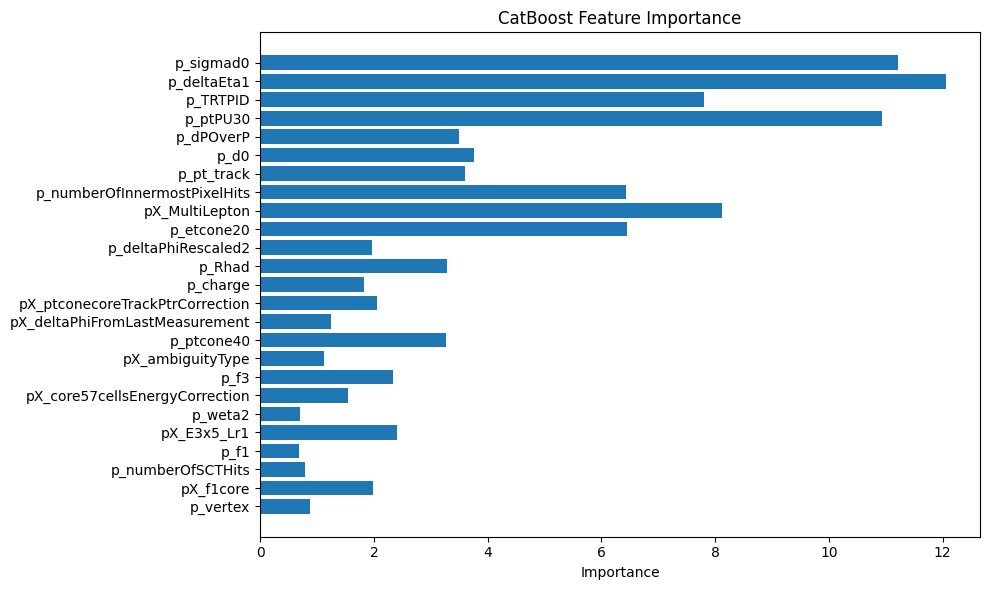

In [ ]:
feature_importance = cat_model.get_feature_importance()
plt.figure(figsize=(10, 6))
plt.barh(top_25_features[::-1], feature_importance[::-1])
plt.title("CatBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [ ]:
# Use the same top 25 features from test data
final_cat_pred = cat_model.predict(test_data)
final_cat_prob = cat_model.predict_proba(test_data)[:, 1]

submission_catboost = pd.DataFrame({
    'vars': test_data.index,
    'pred': final_cat_prob
})

In [ ]:
submission_catboost.to_csv("/content/drive/MyDrive/Applied Machine Learning/solutions/Classification_MohammadhadiShahhosseini_CatBoost.csv", index=False, header=False)